# Dimensionality reduction for visualization with Fashion-MNIST

This notebook compares three common methods for reducing high-dimensional data to two dimensions:

- **PCA**: a linear method that preserves directions of high variance.
- **t-SNE**: a nonlinear method that emphasizes local neighborhoods.
- **UMAP**: a nonlinear method that aims to preserve local structure while retaining more global structure than t-SNE.

We first work directly with the 784 raw pixel values of each image.  
An optional final section repeats the analysis using features extracted by a pretrained convolutional neural network.



# Install and import packages

UMAP is not included in the default Colab environment, so we install `umap-learn`.

In [ ]:
!pip -q install umap-learn

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import umap.umap_ as umap

import tensorflow as tf

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load Fashion-MNIST

Fashion-MNIST contains 28 × 28 grayscale images from ten clothing categories.

To keep t-SNE and UMAP reasonably fast, we use a balanced subset of the test data.

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = np.array([
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
])

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 2us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training set: (60000, 28, 28)
Test set: (10000, 28, 28)


### Select a balanced subset

The default is **500 images per class**, giving 5,000 observations in total.

This is large enough to reveal structure but still practical for a classroom notebook.

In [ ]:
N_PER_CLASS = 500

selected_indices = []

for class_id in range(10):
    class_indices = np.where(y_test == class_id)[0]
    chosen = np.random.choice(
        class_indices,
        size=N_PER_CLASS,
        replace=False
    )
    selected_indices.extend(chosen)

selected_indices = np.array(selected_indices)
np.random.shuffle(selected_indices)

X = X_test[selected_indices]
y = y_test[selected_indices]

print("Subset shape:", X.shape)
print("Class counts:")
print(pd.Series(class_names[y]).value_counts().sort_index())

Subset shape: (5000, 28, 28)
Class counts:
Ankle boot     500
Bag            500
Coat           500
Dress          500
Pullover       500
Sandal         500
Shirt          500
Sneaker        500
T-shirt/top    500
Trouser        500
Name: count, dtype: int64


# Inspect example images

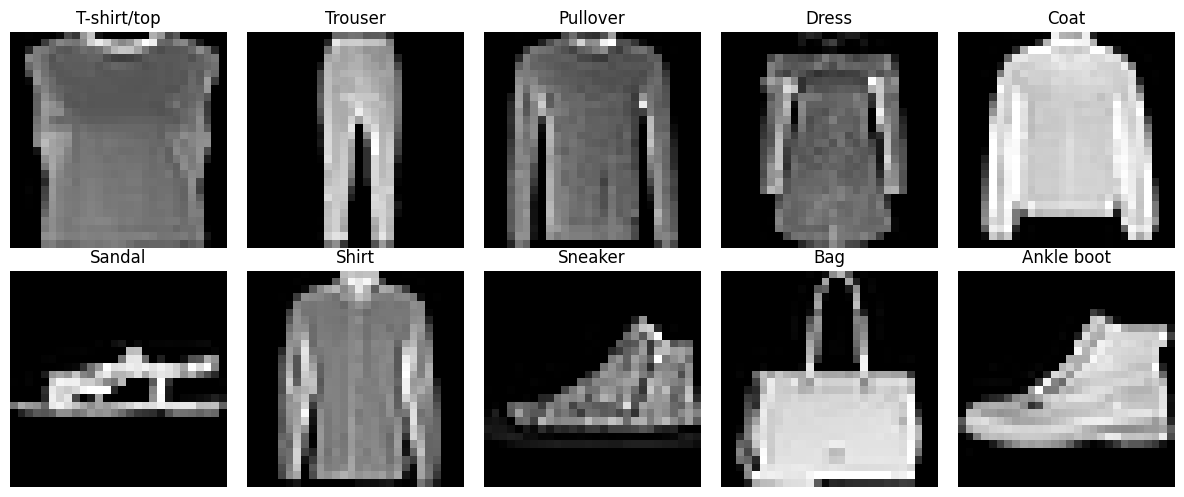

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for class_id, ax in enumerate(axes.ravel()):
    idx = np.where(y == class_id)[0][0]
    ax.imshow(X[idx], cmap="gray")
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

# Prepare the raw-pixel feature matrix

Each 28 × 28 image is flattened into a vector of 784 pixel values.

We divide by 255 so that pixel values lie between 0 and 1.

For this dataset, standardizing every pixel to zero mean and unit variance is not essential and may strongly amplify nearly constant background pixels. We therefore use normalized pixel intensities directly.

In [ ]:
X_pixels = X.reshape(len(X), -1).astype("float32") / 255.0

print("Feature matrix:", X_pixels.shape)
print("Minimum pixel value:", X_pixels.min())
print("Maximum pixel value:", X_pixels.max())

Feature matrix: (5000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# Helper function for two-dimensional plots

In [ ]:
def plot_embedding(embedding, labels, title, class_names=class_names):
    plt.figure(figsize=(10, 8))

    scatter = plt.scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=labels,
        cmap="tab10",
        s=10,
        alpha=0.7
    )

    handles, _ = scatter.legend_elements(num=10)
    plt.legend(
        handles,
        class_names,
        title="Class",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.title(title)
    plt.tight_layout()
    plt.show()

# Dimensionality reduction from raw pixels

# PCA

PCA finds orthogonal directions that explain as much variance as possible.

Because it is linear, PCA is fast and deterministic. It provides a useful baseline, but it cannot unfold nonlinear manifolds.

Runtime: 0.31 seconds
Variance explained by the first two components: 0.468


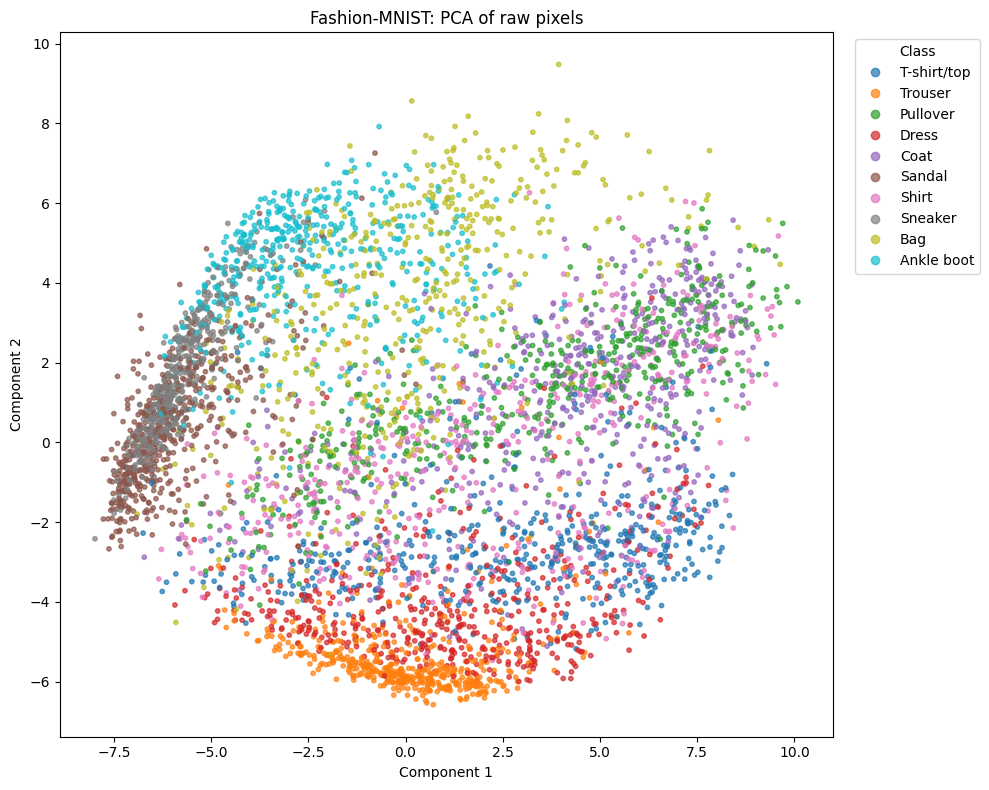

In [ ]:
start = time.time()

pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_pixels)

elapsed = time.time() - start

print(f"Runtime: {elapsed:.2f} seconds")
print(
    "Variance explained by the first two components:",
    f"{pca_2d.explained_variance_ratio_.sum():.3f}"
)

plot_embedding(
    X_pca_2d,
    y,
    "Fashion-MNIST: PCA of raw pixels"
)

### Examine how much variance is retained

A two-dimensional PCA projection generally preserves only a modest fraction of the total variance.

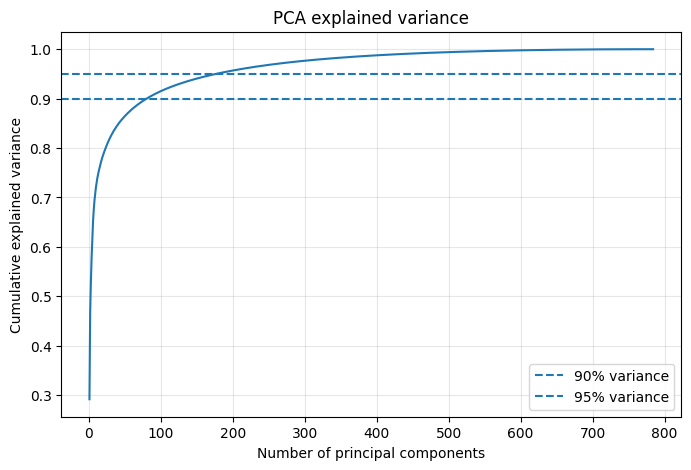

Components required for 90% variance: 81
Components required for 95% variance: 177


In [ ]:
pca_full = PCA().fit(X_pixels)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA explained variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for threshold in [0.90, 0.95]:
    n_components = np.argmax(cumulative_variance >= threshold) + 1
    print(f"Components required for {threshold:.0%} variance: {n_components}")

#  t-SNE

t-SNE constructs a low-dimensional representation in which nearby points in the original feature space tend to remain nearby.

Important interpretation rule:

> Distances between nearby points are meaningful, but the sizes, shapes, and distances between distant clusters should not be over-interpreted.

For speed and noise reduction, it is common to apply PCA before t-SNE. We first reduce 784 pixels to 50 PCA components, then apply t-SNE.

In [ ]:
pca_50 = PCA(n_components=50, random_state=RANDOM_STATE)
X_pca_50 = pca_50.fit_transform(X_pixels)

print(
    "Variance retained in 50 PCA components:",
    f"{pca_50.explained_variance_ratio_.sum():.3f}"
)

Variance retained in 50 PCA components: 0.864


Runtime: 44.39 seconds


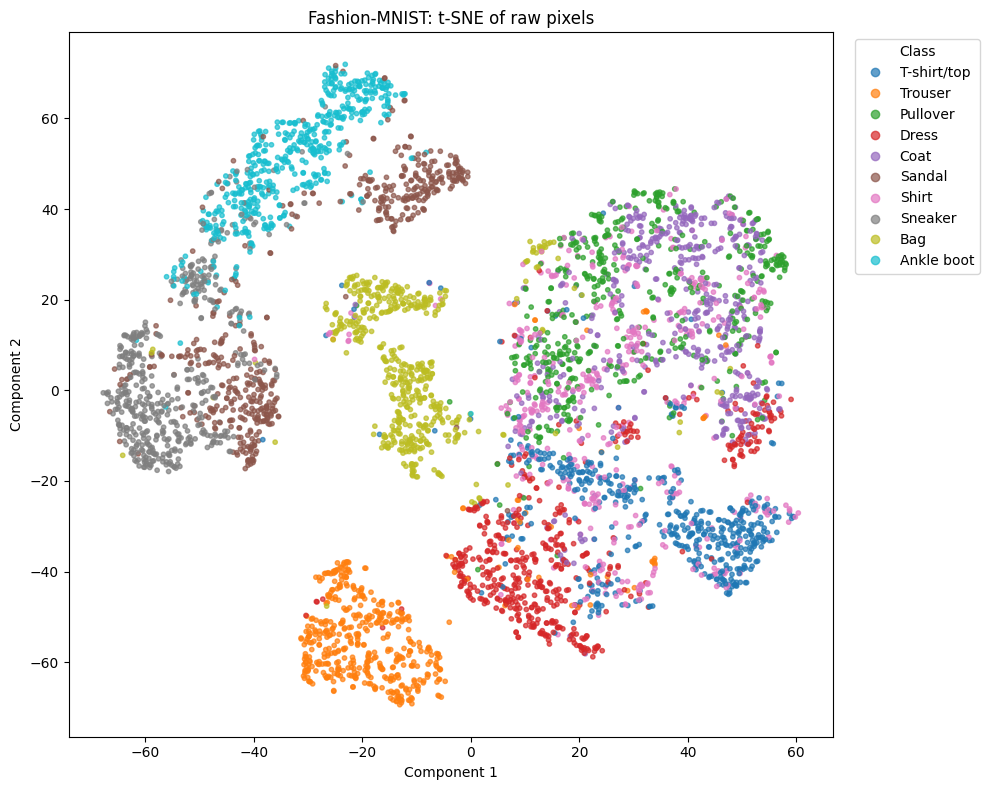

In [ ]:
start = time.time()

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    max_iter=1000,
    random_state=RANDOM_STATE
)

X_tsne_2d = tsne.fit_transform(X_pca_50)

elapsed = time.time() - start
print(f"Runtime: {elapsed:.2f} seconds")

plot_embedding(
    X_tsne_2d,
    y,
    "Fashion-MNIST: t-SNE of raw pixels"
)

### Optional experiment: effect of perplexity

Perplexity roughly controls the neighborhood scale considered by t-SNE.

Try values such as 5, 30, and 50. The visualization can change substantially, which is an important teaching point.

In [ ]:
# Uncomment to compare several perplexity values.
#
# for perplexity in [5, 30, 50]:
#     tsne = TSNE(
#         n_components=2,
#         perplexity=perplexity,
#         learning_rate="auto",
#         init="pca",
#         max_iter=1000,
#         random_state=RANDOM_STATE
#     )
#     embedding = tsne.fit_transform(X_pca_50)
#     plot_embedding(
#         embedding,
#         y,
#         f"t-SNE of raw pixels, perplexity={perplexity}"
#     )

# UMAP

UMAP also builds a neighborhood graph, but it is usually faster than t-SNE and can preserve somewhat more global structure.

Two important parameters are:

- `n_neighbors`: the scale of the local neighborhood.
- `min_dist`: how tightly points may be packed in the low-dimensional representation.

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Runtime: 8.39 seconds


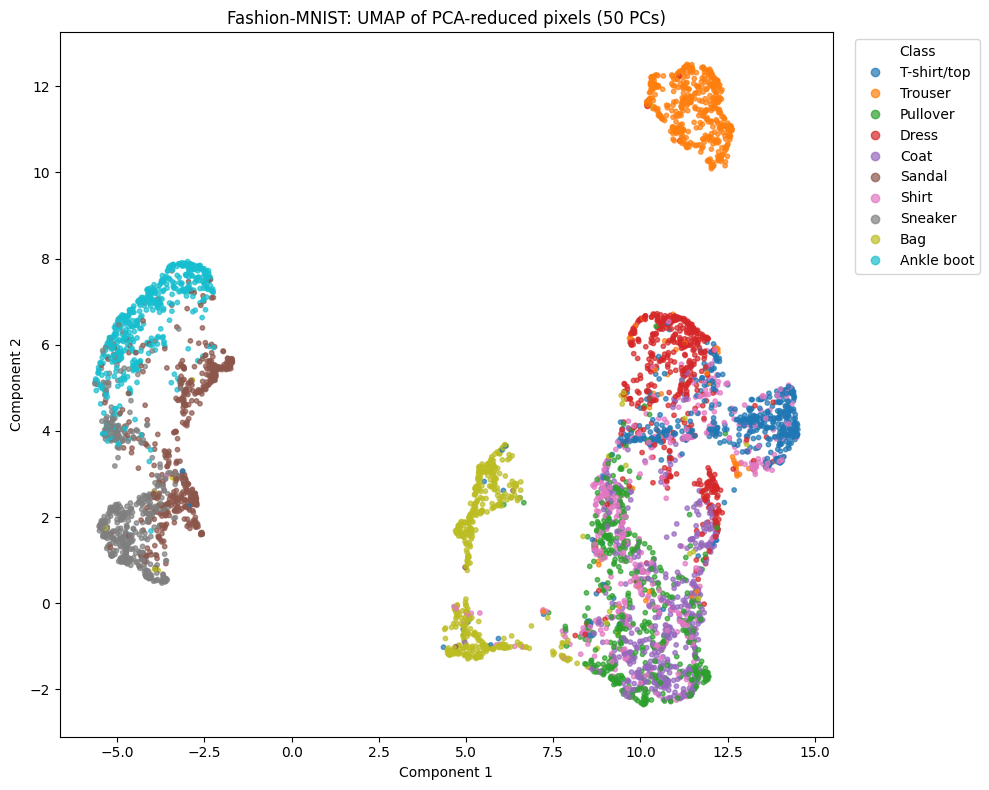

In [ ]:
start = time.time()

# Apply UMAP to the 50-dimensional PCA representation
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=RANDOM_STATE
)

X_umap_2d = umap_model.fit_transform(X_pca_50)

elapsed = time.time() - start
print(f"Runtime: {elapsed:.2f} seconds")

plot_embedding(
    X_umap_2d,
    y,
    "Fashion-MNIST: UMAP of PCA-reduced pixels (50 PCs)"
)

### alternative: UMAP on pixels

/usr/local/lib/python3.12/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Runtime: 17.51 seconds


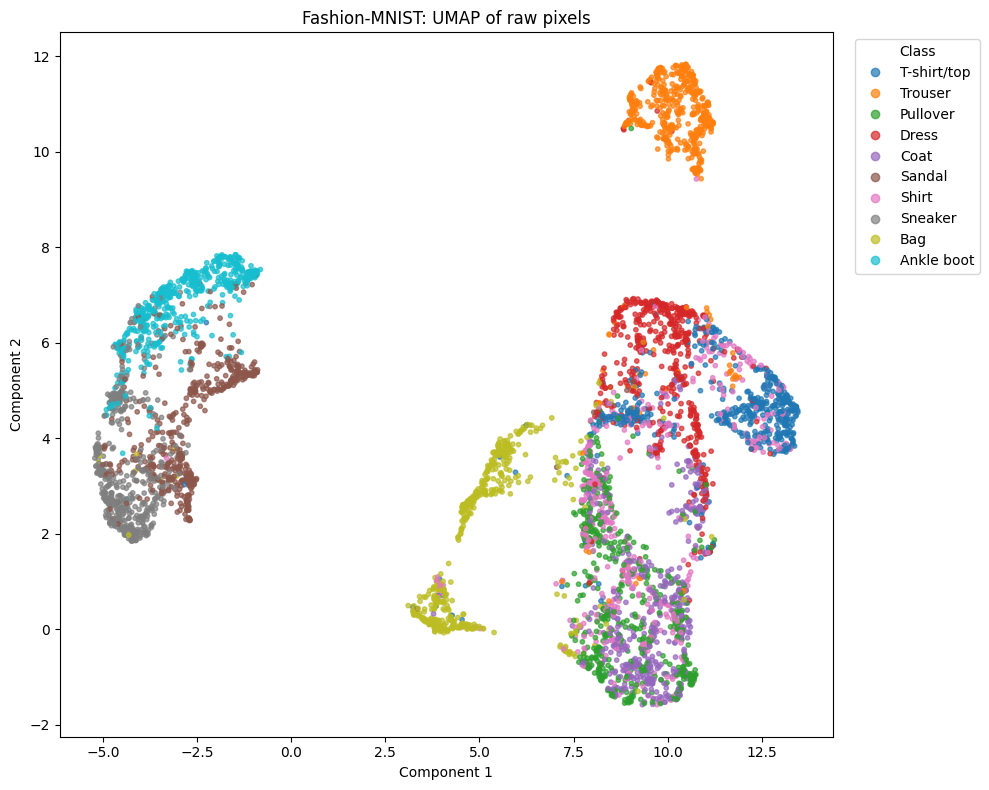

In [ ]:

#start = time.time()

#umap_model = umap.UMAP(
#    n_components=2,
#    n_neighbors=15,
#    min_dist=0.1,
#    metric="euclidean",
#    random_state=RANDOM_STATE
#)
#
#X_umap_2d = umap_model.fit_transform(X_pixels)

#elapsed = time.time() - start
#print(f"Runtime: {elapsed:.2f} seconds")

#plot_embedding(
#    X_umap_2d,
#    y,
#    "Fashion-MNIST: UMAP of raw pixels"
#)

### Optional experiment: local versus global structure

Increasing `n_neighbors` generally emphasizes broader structure. Decreasing `min_dist` allows tighter clusters.

In [ ]:
# Uncomment to compare UMAP settings.
#
# settings = [
#     {"n_neighbors": 5,  "min_dist": 0.1},
#     {"n_neighbors": 15, "min_dist": 0.1},
#     {"n_neighbors": 50, "min_dist": 0.1},
#     {"n_neighbors": 15, "min_dist": 0.0},
#     {"n_neighbors": 15, "min_dist": 0.5},
# ]
#
# for setting in settings:
#     model = umap.UMAP(
#         n_components=2,
#         random_state=RANDOM_STATE,
#         **setting
#     )
#     embedding = model.fit_transform(X_pixels)
#     plot_embedding(
#         embedding,
#         y,
#         "UMAP: "
#         f"n_neighbors={setting['n_neighbors']}, "
#         f"min_dist={setting['min_dist']}"
#     )

# Compare the three embeddings

The same class colors are used in all three plots.

Typical observations:

- PCA separates some broad categories but leaves considerable overlap.
- t-SNE often produces visually compact local clusters.
- UMAP often produces clear clusters while retaining somewhat more large-scale organization.
- The most difficult distinctions are usually among upper-body garments.

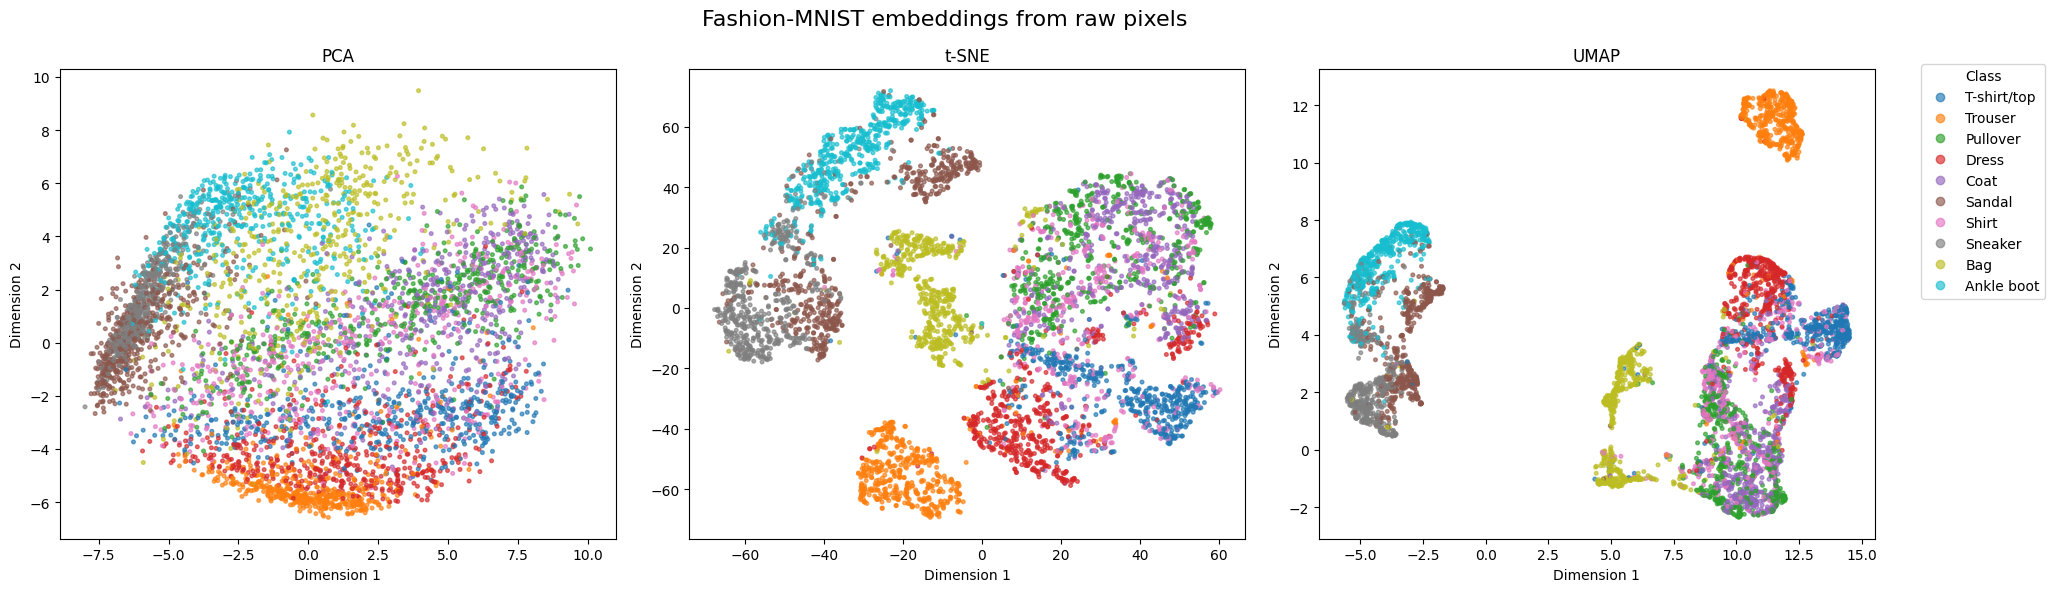

In [ ]:
embeddings = {
    "PCA": X_pca_2d,
    "t-SNE": X_tsne_2d,
    "UMAP": X_umap_2d
}

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

for ax, (name, embedding) in zip(axes, embeddings.items()):
    scatter = ax.scatter(
        embedding[:, 0],
        embedding[:, 1],
        c=y,
        cmap="tab10",
        s=7,
        alpha=0.65
    )
    ax.set_title(name)
    ax.set_xlabel("Dimension 1")
    ax.set_ylabel("Dimension 2")

handles, _ = scatter.legend_elements(num=10)
fig.legend(
    handles,
    class_names,
    title="Class",
    bbox_to_anchor=(1.01, 0.9),
    loc="upper left"
)

fig.suptitle("Fashion-MNIST embeddings from raw pixels", fontsize=16)
plt.tight_layout()
plt.show()

# A cautious quantitative comparison

## Silhouette score

To obtain a simple quantitative measure of class separation, we compute the silhouette score.

For each sample $i$:

- $a(i)$: the average distance from $i$ to all other samples in the same class (intra-class distance).
- $b(i)$: the smallest average distance from $i$ to samples in any other class (nearest-class distance).

The silhouette coefficient of sample $i$ is

$$
s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}.
$$

The overall silhouette score is the average over all samples:

$$
S=\frac{1}{N}\sum_{i=1}^{N}s(i).
$$

### Interpretation

- **$S \approx 1$:** classes are compact and well separated.
- **$S \approx 0$:** classes overlap or lie close together.
- **$S < 0$:** many samples are closer to another class than to their own.

### Important note

Here we compute the silhouette score using the true Fashion-MNIST labels. Therefore, it measures how well the classes are separated in the 2D embedding, not how well the dimensionality reduction algorithm achieved its own objective.

The silhouette score should therefore be viewed only as a supplementary comparison between PCA, t-SNE, and UMAP. In particular, methods such as t-SNE and UMAP are designed to preserve neighborhood relationships rather than maximize class separation.




In [ ]:
for name, embedding in embeddings.items():
    score = silhouette_score(embedding, y)
    print(f"{name:6s}: silhouette score = {score:.3f}")

PCA   : silhouette score = -0.033
t-SNE : silhouette score = 0.148
UMAP  : silhouette score = 0.178
